<a href="https://colab.research.google.com/github/SoniaTabassum/SolarGuard-AI/blob/main/SolarguardAI_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
#Mount Drive and unzip:

ZIP_PATH = "/content/drive/MyDrive/SolarguardAiproject/solar.zip"
!unzip -q "{ZIP_PATH}" -d /content/solar

In [3]:
#Find your class folders:

import os
for root, dirs, files in os.walk("/content/solar"):
    print(root, "->", len(files), "files,", len(dirs), "subfolders")

/content/solar -> 0 files, 1 subfolders
/content/solar/Faulty_solar_panel -> 0 files, 6 subfolders
/content/solar/Faulty_solar_panel/Bird-drop -> 192 files, 1 subfolders
/content/solar/Faulty_solar_panel/Bird-drop/New -> 16 files, 0 subfolders
/content/solar/Faulty_solar_panel/Dusty -> 191 files, 0 subfolders
/content/solar/Faulty_solar_panel/Physical-Damage -> 70 files, 0 subfolders
/content/solar/Faulty_solar_panel/Electrical-damage -> 104 files, 0 subfolders
/content/solar/Faulty_solar_panel/Clean -> 194 files, 0 subfolders
/content/solar/Faulty_solar_panel/Snow-Covered -> 124 files, 0 subfolders


In [4]:
#Set the data path and list classes:

from pathlib import Path

DATA_DIR = "/content/solar/Faulty_solar_panel"
classes = sorted([d.name for d in Path(DATA_DIR).iterdir() if d.is_dir()])
counts = {c: len([p for p in (Path(DATA_DIR)/c).glob("*") if p.suffix.lower() in ['.jpg','.jpeg','.png']]) for c in classes}
print(classes)
print(counts, "TOTAL:", sum(counts.values()))

['Bird-drop', 'Clean', 'Dusty', 'Electrical-damage', 'Physical-Damage', 'Snow-Covered']
{'Bird-drop': 191, 'Clean': 193, 'Dusty': 190, 'Electrical-damage': 103, 'Physical-Damage': 69, 'Snow-Covered': 123} TOTAL: 869


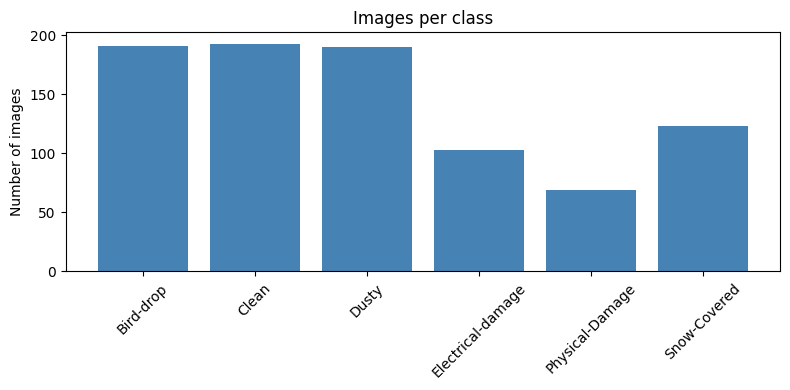

In [5]:
#Explore the data : Class distribution chart:

import matplotlib.pyplot as plt
plt.figure(figsize=(8,4))
plt.bar(counts.keys(), counts.values(), color="steelblue")
plt.xticks(rotation=45); plt.ylabel("Number of images")
plt.title("Images per class"); plt.tight_layout(); plt.show()

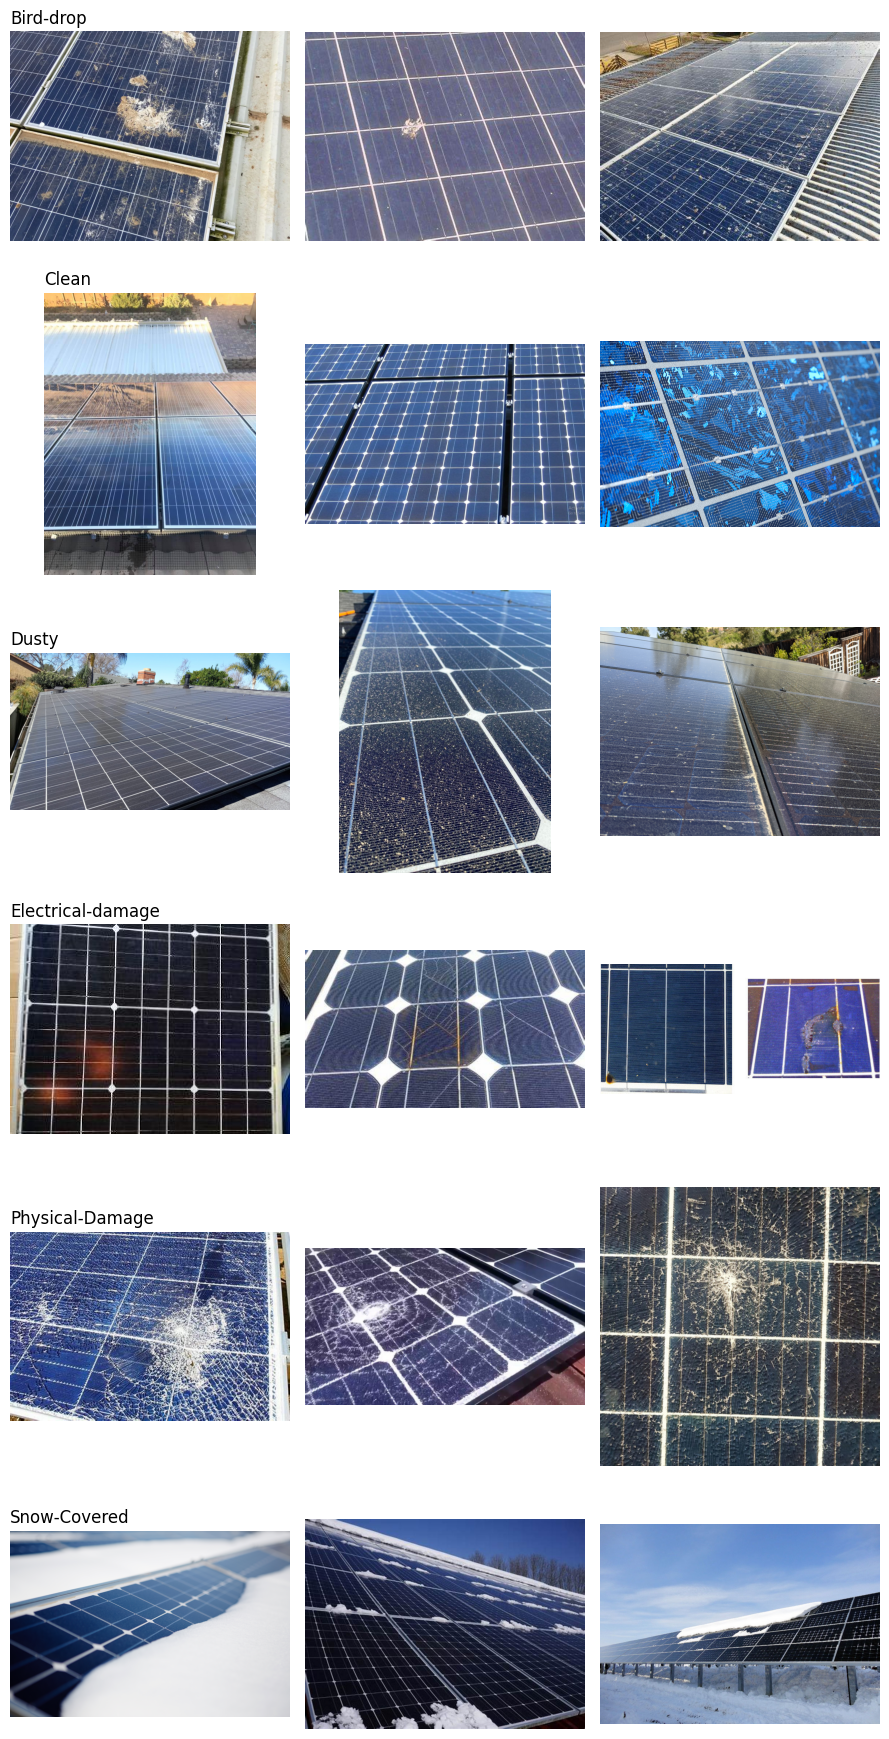

In [6]:
#Sample Images:

import cv2, random
fig, axes = plt.subplots(len(classes), 3, figsize=(9, 3*len(classes)))
for r, c in enumerate(classes):
    files = [p for p in (Path(DATA_DIR)/c).glob("*") if p.suffix.lower() in ['.jpg','.jpeg','.png']]
    for k, p in enumerate(random.sample(files, min(3, len(files)))):
        img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        axes[r][k].imshow(img); axes[r][k].axis("off")
        if k == 0: axes[r][k].set_title(c, loc="left")
plt.tight_layout(); plt.show()

In [7]:
#Image Sizes:

sizes = []
for c in classes:
    for p in list((Path(DATA_DIR)/c).glob("*"))[:30]:
        img = cv2.imread(str(p))
        if img is not None: sizes.append(img.shape[:2])
print("Different sizes seen:", len(set(sizes)))
print(sizes[:10])

Different sizes seen: 138
[(847, 1500), (459, 816), (355, 474), (740, 986), (587, 591), (533, 533), (720, 960), (250, 190), (632, 474), (194, 259)]


In [8]:
#Preprocessing: Load, convert and resize all images:

import numpy as np
IMG_SIZE = 224
X, y = [], []
for idx, c in enumerate(classes):
    for p in (Path(DATA_DIR)/c).glob("*"):
        if p.suffix.lower() not in ['.jpg','.jpeg','.png']: continue
        img = cv2.imread(str(p))
        if img is None: continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        X.append(img); y.append(idx)
X, y = np.array(X), np.array(y)
print(X.shape, y.shape)

(869, 224, 224, 3) (869,)


In [9]:
#Stratified 70/15/15 split:

from sklearn.model_selection import train_test_split
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)
print("Train:", X_train.shape[0], "Val:", X_val.shape[0], "Test:", X_test.shape[0])

Train: 608 Val: 130 Test: 131


In [10]:
#Save to Drive:

os.makedirs("/content/drive/MyDrive/SolarGuard", exist_ok=True)
for name, arr in [("X_train",X_train),("X_val",X_val),("X_test",X_test),
                  ("y_train",y_train),("y_val",y_val),("y_test",y_test)]:
    np.save(f"/content/drive/MyDrive/SolarGuard/{name}.npy", arr)

In [11]:
#ML baseline (HOG + color histogram)
#Extract features:

from skimage.feature import hog

def extract_features(img):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    gray = cv2.resize(gray, (128, 128))
    h = hog(gray, orientations=9, pixels_per_cell=(16,16), cells_per_block=(2,2))
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    hist = cv2.calcHist([hsv],[0,1,2],None,[8,8,8],[0,180,0,256,0,256]).flatten()
    hist = hist / (hist.sum() + 1e-7)
    return np.concatenate([h, hist])

F_train = np.array([extract_features(i) for i in X_train])
F_val   = np.array([extract_features(i) for i in X_val])
print(F_train.shape)

(608, 2276)


In [12]:
#Train and evaluate the ML models:

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

scaler = StandardScaler().fit(F_train)      # fit on TRAIN only
Fs_train, Fs_val = scaler.transform(F_train), scaler.transform(F_val)

models = {
    "Random Forest": (RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42), F_train, F_val),
    "SVM": (SVC(kernel='rbf', class_weight='balanced'), Fs_train, Fs_val),
    "KNN": (KNeighborsClassifier(n_neighbors=5), Fs_train, Fs_val),
}
results = {}
for name, (m, Xtr, Xv) in models.items():
    m.fit(Xtr, y_train)
    pred = m.predict(Xv)
    results[name] = (accuracy_score(y_val, pred), f1_score(y_val, pred, average="macro"))
    print("=====", name, "=====")
    print(classification_report(y_val, pred, target_names=classes, zero_division=0))

===== Random Forest =====
                   precision    recall  f1-score   support

        Bird-drop       0.68      0.68      0.68        28
            Clean       0.54      0.69      0.61        29
            Dusty       0.58      0.79      0.67        28
Electrical-damage       0.77      0.62      0.69        16
  Physical-Damage       1.00      0.27      0.43        11
     Snow-Covered       0.82      0.50      0.62        18

         accuracy                           0.64       130
        macro avg       0.73      0.59      0.62       130
     weighted avg       0.68      0.64      0.63       130

===== SVM =====
                   precision    recall  f1-score   support

        Bird-drop       0.60      0.64      0.62        28
            Clean       0.56      0.69      0.62        29
            Dusty       0.60      0.54      0.57        28
Electrical-damage       0.67      0.75      0.71        16
  Physical-Damage       1.00      0.36      0.53        11
     Snow-

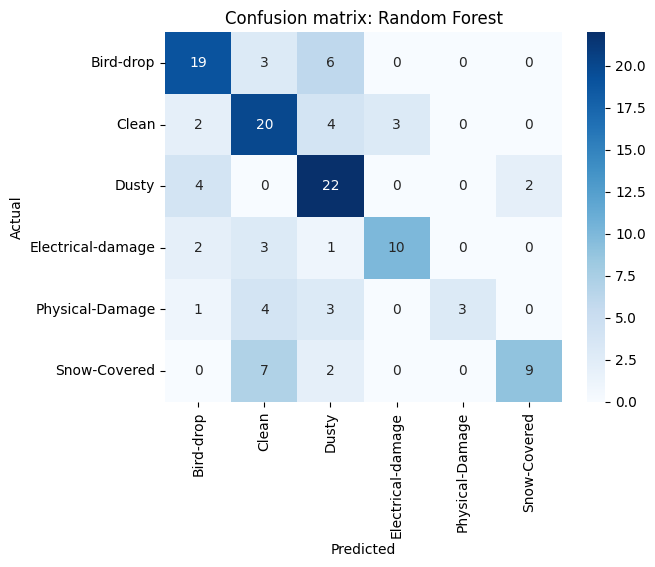

In [13]:
#Confusion matrix for the best model:

import seaborn as sns
best = max(results, key=lambda k: results[k][1])
m, Xtr, Xv = models[best]
cm = confusion_matrix(y_val, m.predict(Xv))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=classes, yticklabels=classes, cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"Confusion matrix: {best}"); plt.show()

In [14]:
#DL baseline (CNN from scratch)
#Build and train the CNN:

import tensorflow as tf
from tensorflow.keras import layers, models as kmodels

cnn = kmodels.Sequential([
    layers.Input((224,224,3)),
    layers.Rescaling(1./255),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.Conv2D(32,3,activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(64,3,activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(128,3,activation='relu'), layers.MaxPooling2D(),
    layers.Flatten(), layers.Dropout(0.5),
    layers.Dense(128, activation='relu'),
    layers.Dense(len(classes), activation='softmax')
])
cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = cnn.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=32)

Epoch 1/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 8s 77ms/step - accuracy: 0.2829 - loss: 1.7849 - val_accuracy: 0.4077 - val_loss: 1.5025
Epoch 2/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - accuracy: 0.4013 - loss: 1.4719 - val_accuracy: 0.4538 - val_loss: 1.4640
Epoch 3/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - accuracy: 0.4655 - loss: 1.3618 - val_accuracy: 0.4846 - val_loss: 1.4771
Epoch 4/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - accuracy: 0.4984 - loss: 1.2991 - val_accuracy: 0.5308 - val_loss: 1.3196
Epoch 5/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - accuracy: 0.5132 - loss: 1.2529 - val_accuracy: 0.5846 - val_loss: 1.2948
Epoch 6/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - accuracy: 0.5674 - loss: 1.1954 - val_accuracy: 0.4846 - val_loss: 1.4055
Epoch 7/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - accuracy: 0.5395 - loss: 1.2248 - val_accuracy: 0.5154 - val_loss: 1.3280
Epoch 8/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - accuracy: 0.5773 - loss: 1.1292 - val_accuracy: 0.6154 - v

In [15]:
#Trying new CNN model with some changes to explore how diff changes in model change accuracy:

cnn = kmodels.Sequential([
    layers.Input((224,224,3)),
    layers.Rescaling(1./255),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.Conv2D(32,3,activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(64,3,activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(128,3,activation='relu'), layers.MaxPooling2D(),
    layers.Flatten(), layers.Dropout(0.5),
    layers.Dense(128, activation='relu'),
    layers.Dense(len(classes), activation='softmax')
])
cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = cnn.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=32)

Epoch 1/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 75ms/step - accuracy: 0.2352 - loss: 2.2852 - val_accuracy: 0.3769 - val_loss: 1.6951
Epoch 2/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.3865 - loss: 1.5634 - val_accuracy: 0.4462 - val_loss: 1.5231
Epoch 3/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.4095 - loss: 1.4518 - val_accuracy: 0.5308 - val_loss: 1.4022
Epoch 4/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.4688 - loss: 1.3481 - val_accuracy: 0.4538 - val_loss: 1.4683
Epoch 5/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.5099 - loss: 1.2702 - val_accuracy: 0.4846 - val_loss: 1.3854
Epoch 6/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.5411 - loss: 1.2454 - val_accuracy: 0.5538 - val_loss: 1.2762
Epoch 7/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.5411 - loss: 1.1925 - val_accuracy: 0.5462 - val_loss: 1.2142
Epoch 8/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.5592 - loss: 1.1400 - val_accuracy: 0.5462 - v

In [16]:
#Change 1:Added one more hidden layer to new CNN model:

cnn_deep = kmodels.Sequential([
    layers.Input((224,224,3)),
    layers.Rescaling(1./255),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.Conv2D(32,3,activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(64,3,activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(128,3,activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(256,3,activation='relu'), layers.MaxPooling2D(),   # <- ADDED
    layers.Flatten(), layers.Dropout(0.5),
    layers.Dense(128, activation='relu'),
    layers.Dense(len(classes), activation='softmax')
])
cnn_deep.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_deep = cnn_deep.fit(X_train, y_train, validation_data=(X_val, y_val),
                            epochs=20, batch_size=32)

Epoch 1/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - accuracy: 0.2171 - loss: 1.7917 - val_accuracy: 0.2385 - val_loss: 1.7286
Epoch 2/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.3602 - loss: 1.6120 - val_accuracy: 0.4308 - val_loss: 1.5068
Epoch 3/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.3997 - loss: 1.4789 - val_accuracy: 0.4769 - val_loss: 1.4548
Epoch 4/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.4605 - loss: 1.3954 - val_accuracy: 0.4846 - val_loss: 1.4175
Epoch 5/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.4671 - loss: 1.3294 - val_accuracy: 0.4923 - val_loss: 1.3543
Epoch 6/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.4934 - loss: 1.2888 - val_accuracy: 0.4615 - val_loss: 1.5550
Epoch 7/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.4605 - loss: 1.3481 - val_accuracy: 0.5231 - val_loss: 1.3457
Epoch 8/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.5164 - loss: 1.2219 - val_accuracy: 0.5538 - v

In [17]:
#Change 2: remove dropout:

cnn_drop = kmodels.Sequential([
    layers.Input((224,224,3)),
    layers.Rescaling(1./255),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.Conv2D(32,3,activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(64,3,activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(128,3,activation='relu'), layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(len(classes), activation='softmax')
])
cnn_drop.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_drop = cnn_drop.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=32)

Epoch 1/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 76ms/step - accuracy: 0.2352 - loss: 2.0706 - val_accuracy: 0.3385 - val_loss: 1.6313
Epoch 2/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.3503 - loss: 1.5953 - val_accuracy: 0.4846 - val_loss: 1.5165
Epoch 3/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.4079 - loss: 1.4906 - val_accuracy: 0.4385 - val_loss: 1.4940
Epoch 4/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.4671 - loss: 1.3250 - val_accuracy: 0.3538 - val_loss: 1.6046
Epoch 5/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.5115 - loss: 1.2687 - val_accuracy: 0.4615 - val_loss: 1.4014
Epoch 6/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.5493 - loss: 1.1741 - val_accuracy: 0.5308 - val_loss: 1.3272
Epoch 7/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.5806 - loss: 1.1282 - val_accuracy: 0.5308 - val_loss: 1.3149
Epoch 8/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.5691 - loss: 1.1209 - val_accuracy: 0.5692 - v

In [18]:
#Change 3: more epochs (from 20 to 50):

cnn_epo50 = kmodels.Sequential([
    layers.Input((224,224,3)),
    layers.Rescaling(1./255),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.Conv2D(32,3,activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(64,3,activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(128,3,activation='relu'), layers.MaxPooling2D(),
    layers.Flatten(), layers.Dropout(0.5),
    layers.Dense(128, activation='relu'),
    layers.Dense(len(classes), activation='softmax')
])
cnn_epo50.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_epo50 = cnn_epo50.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=50, batch_size=32)

Epoch 1/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 78ms/step - accuracy: 0.2599 - loss: 1.7782 - val_accuracy: 0.4308 - val_loss: 1.5643
Epoch 2/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.3799 - loss: 1.5529 - val_accuracy: 0.4154 - val_loss: 1.4573
Epoch 3/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.4523 - loss: 1.3825 - val_accuracy: 0.4692 - val_loss: 1.3622
Epoch 4/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.5181 - loss: 1.2744 - val_accuracy: 0.4692 - val_loss: 1.3689
Epoch 5/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.5428 - loss: 1.2007 - val_accuracy: 0.4615 - val_loss: 1.4735
Epoch 6/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.5510 - loss: 1.1729 - val_accuracy: 0.5308 - val_loss: 1.3381
Epoch 7/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.5691 - loss: 1.1538 - val_accuracy: 0.5462 - val_loss: 1.3658
Epoch 8/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.5806 - loss: 1.0831 - val_accuracy: 0.6308 - v

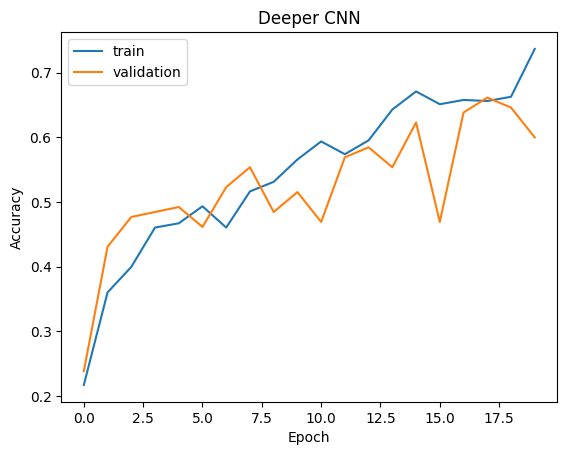

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
                   precision    recall  f1-score   support

        Bird-drop       0.52      0.39      0.45        28
            Clean       0.55      0.76      0.64        29
            Dusty       0.62      0.71      0.67        28
Electrical-damage       0.64      0.44      0.52        16
  Physical-Damage       0.83      0.45      0.59        11
     Snow-Covered       0.65      0.72      0.68        18

         accuracy                           0.60       130
        macro avg       0.64      0.58      0.59       130
     weighted avg       0.61      0.60      0.59       130



In [19]:
#Learning curves and CNN evaluation of new CNN Model:

plt.plot(history_deep.history['accuracy'], label="train")
plt.plot(history_deep.history['val_accuracy'], label="validation")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.title("Deeper CNN"); plt.show()

deep_pred = np.argmax(cnn_deep.predict(X_val), axis=1)
print(classification_report(y_val, deep_pred, target_names=classes, zero_division=0))
results["CNN deeper (4 blocks)"] = (accuracy_score(y_val, deep_pred),
                                    f1_score(y_val, deep_pred, average="macro"))

cnn_deep.save("/content/drive/MyDrive/SolarGuard/cnn_deep.keras")

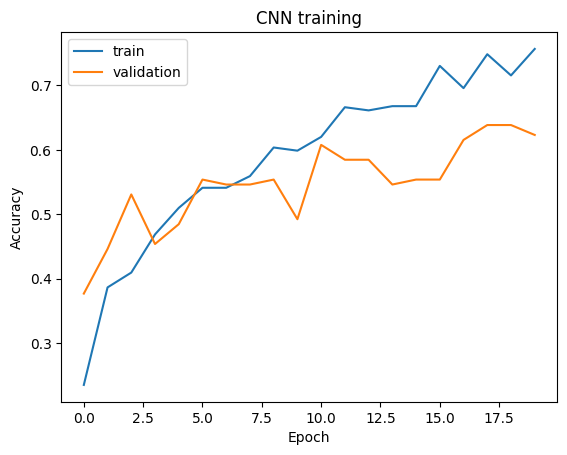

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
                   precision    recall  f1-score   support

        Bird-drop       0.68      0.54      0.60        28
            Clean       0.55      0.72      0.63        29
            Dusty       0.69      0.71      0.70        28
Electrical-damage       0.50      0.50      0.50        16
  Physical-Damage       0.56      0.45      0.50        11
     Snow-Covered       0.75      0.67      0.71        18

         accuracy                           0.62       130
        macro avg       0.62      0.60      0.61       130
     weighted avg       0.63      0.62      0.62       130



In [20]:
#Learning curves and CNN evaluation of first CNN Model:

plt.plot(history.history['accuracy'], label="train")
plt.plot(history.history['val_accuracy'], label="validation")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.title("CNN training"); plt.show()

cnn_pred = np.argmax(cnn.predict(X_val), axis=1)
print(classification_report(y_val, cnn_pred, target_names=classes, zero_division=0))
results["CNN (scratch)"] = (accuracy_score(y_val, cnn_pred), f1_score(y_val, cnn_pred, average="macro"))

cnn.save("/content/drive/MyDrive/SolarGuard/cnn_baseline.keras")

In [21]:
 #Comparison table:

import pandas as pd
df = pd.DataFrame(results, index=["Val Accuracy","Val Macro-F1"]).T.round(3)
print(df)

                       Val Accuracy  Val Macro-F1
Random Forest                 0.638         0.615
SVM                           0.615         0.612
KNN                           0.308         0.234
CNN deeper (4 blocks)         0.600         0.591
CNN (scratch)                 0.623         0.606


In [23]:
#Prediction function (Working Pipeline):

def predict_image(path):
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224, 224))
    probs = cnn.predict(img[None, ...], verbose=0)[0]
    return classes[int(np.argmax(probs))], round(float(np.max(probs)), 3)

sample = next((Path(DATA_DIR)/classes[1]).glob("*"))
print("True class:", classes[1], "| Prediction:", predict_image(str(sample)))

True class: Clean | Prediction: ('Clean', 0.882)
